# Clustering por Densidad (HDBSCAN), Bautizo Zero-Shot de Centroides y Comparación con YouTube

Este notebook es **100 % autocontenido** (no depende del servidor ni de `VideoCatalog`): carga directamente los archivos `.parquet` y `.sqlite3` de `data/` y ejecuta paso a paso:

1. **Reconstrucción de las categorías oficiales de YouTube (`Vertical1`)** a partir de las etiquetas de YouTube-8M ($c_i = \operatorname{moda}\{\mathrm{Vertical1}(j) : j \in \ell_i\}$).
2. **Clustering no supervisado con HDBSCAN** sobre el espacio UMAP 3D y cálculo de los **centroides esféricos** $\mu_k \in \mathbb{S}^{767}$ en el espacio original de 768 dimensiones de `EmbeddingGemma 2`.
3. **Cálculo explícito de métricas de evaluación externa e interna:**
   - **Pureza de cada cluster** $\operatorname{Purity}(C_k) = \frac{1}{|C_k|} \max_{v} |C_k \cap Y_v|$ y **Pureza global ponderada** $\sum_k \frac{|C_k|}{N} \operatorname{Purity}(C_k)$. *(Nota: HDBSCAN es un algoritmo no supervisado; solo devuelve `labels_` y `probabilities_`. La pureza, NMI, ARI y Silueta las calculamos explícitamente cruzando los clusters contra las categorías de YouTube).*
   - **Información Mutua Normalizada (NMI)** y **Adjusted Rand Index (ARI)**.
   - **Coeficiente de Silueta** en $\mathbb{S}^{767}$ (distancia coseno) y en $\mathbb{R}^3$ (UMAP).
4. **Bautizo automático Zero-Shot de cada centroide** cruzando $\mu_k$ contra el vocabulario embebido (`data/emb_vocab.parquet`) y los prototipos de tags (`tags`).
5. **Visualización:** Matriz de contingencia normalizada y Diagrama de flujo semántico (Alluvial/Sankey).

In [1]:
import json
import sqlite3
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.path import Path as MplPath
from sklearn.cluster import HDBSCAN
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    silhouette_score,
)

DATA_DIR = Path("data")

# 1. Cargar embeddings de texto base (34.788 videos de YT-8M)
emb_df = (
    pd.read_parquet(DATA_DIR / "emb_text.parquet", columns=["youtube_id", "emb"])
    .dropna(subset=["youtube_id"])
    .drop_duplicates("youtube_id")
    .reset_index(drop=True)
)
base_ids = emb_df["youtube_id"].astype(str).tolist()
base_set = set(base_ids)
base_vectors = np.stack(emb_df["emb"].to_numpy()).astype(np.float32)

# 2. Cargar metadatos hidratados y vocabulario de YT-8M
meta_df = pd.read_parquet(
    DATA_DIR / "yt8m_hydrated.parquet",
    columns=["youtube_id", "title", "labels", "tags"],
).dropna(subset=["youtube_id"])

vocab_df = pd.read_parquet(
    DATA_DIR / "emb_vocab.parquet",
    columns=["Index", "Name", "Vertical1", "emb"],
)
vocab_names = vocab_df["Name"].astype(str).to_numpy()
vocab_vectors = np.stack(vocab_df["emb"].to_numpy()).astype(np.float32)
label_to_vertical = dict(zip(vocab_df["Index"].astype(int), vocab_df["Vertical1"]))

# Asignar a cada video base su categoría oficial de YouTube: moda(Vertical1)
verticals = {}
for yid, labels in zip(meta_df["youtube_id"].astype(str), meta_df["labels"]):
    v_names = [
        label_to_vertical[int(l)]
        for l in (labels if labels is not None else [])
        if int(l) in label_to_vertical and isinstance(label_to_vertical[int(l)], str)
    ]
    if v_names:
        verticals[yid] = Counter(v_names).most_common(1)[0][0]

print(f"Videos base YT-8M: {len(base_ids):,} | Vocabulario YT-8M: {len(vocab_names):,} entidades")

Videos base YT-8M: 34,788 | Vocabulario YT-8M: 3,806 entidades


## 1. Integración de videos modernos (`webapp_catalog.sqlite3`) y coordenadas UMAP 3D

Cargamos también los videos modernos recolectados en `data/webapp_catalog.sqlite3` y las coordenadas UMAP 3D vigentes desde `data/maps/current.json`. Para los videos modernos (que no provienen de YT-8M y por tanto no tienen la columna `labels` de 2018), estimamos su categoría de referencia proyectándolos contra los centroides de las 24 categorías conocidas.

In [2]:
# Centroides de las categorías oficiales de YouTube sobre los videos base
cat_indices = defaultdict(list)
for i, yid in enumerate(base_ids):
    v = verticals.get(yid)
    if v and v != "(Unknown)":
        cat_indices[v].append(i)

known_cats = sorted(cat_indices.keys())
yt_cat_centroids = np.zeros((len(known_cats), 768), dtype=np.float32)
for k, cname in enumerate(known_cats):
    c_vec = base_vectors[cat_indices[cname]].mean(axis=0)
    c_vec /= max(float(np.linalg.norm(c_vec)), 1e-12)
    yt_cat_centroids[k] = c_vec

# Cargar videos modernos desde SQLite
sqlite_path = DATA_DIR / "webapp_catalog.sqlite3"
received_ids, received_vecs = [], []
if sqlite_path.exists():
    with sqlite3.connect(sqlite_path) as db:
        rows = db.execute("SELECT youtube_id, embedding FROM received ORDER BY received_at").fetchall()
    for yid, blob in rows:
        if yid not in base_set:
            vec = np.frombuffer(blob, dtype=np.float32).copy()
            received_ids.append(str(yid))
            received_vecs.append(vec)

all_ids = base_ids + received_ids
X_768 = np.vstack([base_vectors, np.stack(received_vecs)]) if received_vecs else base_vectors

# Asignar categoría de referencia a los videos modernos por similitud con los centroides de YouTube
if received_vecs:
    rec_mat = np.stack(received_vecs)
    best_cat_idx = np.argmax(rec_mat @ yt_cat_centroids.T, axis=1)
    for yid, c_i in zip(received_ids, best_cat_idx):
        verticals[yid] = known_cats[int(c_i)]

yt_cats = np.array([verticals.get(yid, "(Unknown)") for yid in all_ids])

# Cargar coordenadas UMAP 3D vigentes (y proyectar con reducer.joblib los nuevos)
import joblib
current_version = json.loads((DATA_DIR / "maps/current.json").read_text())["version"]
map_dir = DATA_DIR / "maps" / current_version
coords_df = pd.read_parquet(map_dir / "coords.parquet")
coord_lookup = {
    str(r.youtube_id): np.array([r.x, r.y, r.z], dtype=np.float32)
    for r in coords_df.itertuples(index=False)
}

X_3d = np.zeros((len(all_ids), 3), dtype=np.float32)
missing = []
for i, yid in enumerate(all_ids):
    if yid in coord_lookup:
        X_3d[i] = coord_lookup[yid]
    else:
        missing.append(i)

if missing:
    reducer = joblib.load(map_dir / "reducer.joblib")
    X_3d[missing] = reducer.transform(X_768[missing]).astype(np.float32)

N = len(all_ids)
print(f"Total catálogo integrado: {N:,} videos ({len(base_ids):,} base + {len(received_ids):,} modernos)")
print(f"Matriz X_768: {X_768.shape} | Matriz X_3d (UMAP): {X_3d.shape}")

Total catálogo integrado: 36,045 videos (34,788 base + 1,257 modernos)
Matriz X_768: (36045, 768) | Matriz X_3d (UMAP): (36045, 3)


## 2. Ejecución de HDBSCAN y cálculo explícito de Pureza, NMI, ARI y Silueta

`HDBSCAN` es un algoritmo de clustering jerárquico basado en densidad: **solo recibe las coordenadas espaciales** y devuelve:
- `raw_labels`: el ID del cluster asignado a cada punto ($0, 1, \dots, K-1$), o $-1$ para puntos en zonas de baja densidad (*ruido/periferia*).

Para evaluar qué tan coherentes son los clusters descubiertos y compararlos contra las categorías oficiales de YouTube, definimos explícitamente:

1. **Centroides esféricos en 768-d ($\mu_k$):**
   $$\mu_k = \frac{\sum_{i \in C_k} x_i}{\left\|\sum_{i \in C_k} x_i\right\|_2} \in \mathbb{S}^{767}$$
2. **Asignación esférica completa (`assigned_labels`):** los puntos periféricos ($-1$) se asignan al centroide HDBSCAN con mayor similitud coseno en el espacio original de 768 dimensiones: $\hat{k}(i) = \arg\max_k \mu_k^\top x_i$.
3. **Pureza de un cluster ($\operatorname{Purity}(C_k)$) y Pureza media ponderada:**
   $$\operatorname{Purity}(C_k) = \frac{1}{|C_k|} \max_{v \in \mathcal{V}_{\text{YT}}} \big|\{i \in C_k : y_i^{\text{YT}} = v\}\big|, \qquad \operatorname{Purity}_{\text{global}} = \sum_{k=0}^{K-1} \frac{|C_k|}{N} \operatorname{Purity}(C_k)$$

In [3]:
# 1. Ajuste de HDBSCAN sobre el espacio UMAP 3D
hdb = HDBSCAN(min_cluster_size=220, min_samples=30, copy=True)
raw_labels = hdb.fit_predict(X_3d.astype(np.float64))
n_clusters = int(raw_labels.max() + 1)
noise_fraction = float((raw_labels == -1).mean())

# 2. Cálculo de los centroides esféricos en el espacio original de 768 dimensiones
centroids_768 = np.zeros((n_clusters, 768), dtype=np.float32)
centroids_3d = np.zeros((n_clusters, 3), dtype=np.float32)
for k in range(n_clusters):
    mask = raw_labels == k
    mean_vec = X_768[mask].mean(axis=0)
    centroids_768[k] = mean_vec / max(float(np.linalg.norm(mean_vec)), 1e-12)
    centroids_3d[k] = X_3d[mask].mean(axis=0)

# 3. Asignación de puntos periféricos (-1) a su centroide esférico más cercano en 768-d
assigned_labels = raw_labels.copy()
noise_idx = np.flatnonzero(raw_labels == -1)
if len(noise_idx):
    assigned_labels[noise_idx] = np.argmax(X_768[noise_idx] @ centroids_768.T, axis=1)

# 4. Función explícita para calcular la Pureza por cluster y la Pureza global ponderada
def compute_purity(cluster_labels, true_categories):
    per_cluster = {}
    weighted_hits = 0
    total_valid = 0
    for k in sorted(set(cluster_labels)):
        if k < 0:
            continue
        mask = (cluster_labels == k) & (true_categories != "(Unknown)")
        n_k = int(mask.sum())
        if n_k == 0:
            continue
        most_common_cat, dominant_count = Counter(true_categories[mask]).most_common(1)[0]
        purity_k = dominant_count / n_k
        per_cluster[k] = {
            "dominant_vertical": most_common_cat,
            "dominant_count": dominant_count,
            "n_valid": n_k,
            "purity": purity_k,
        }
        weighted_hits += dominant_count
        total_valid += n_k
    global_purity = weighted_hits / max(1, total_valid)
    return global_purity, per_cluster

purity_core, core_stats = compute_purity(raw_labels, yt_cats)
purity_all, all_stats = compute_purity(assigned_labels, yt_cats)

# 5. Cálculo de NMI, ARI y Silueta (comparando la partición de YouTube vs. HDBSCAN)
valid_core = (raw_labels >= 0) & (yt_cats != "(Unknown)")
valid_all = yt_cats != "(Unknown)"

nmi_core = normalized_mutual_info_score(yt_cats[valid_core], raw_labels[valid_core])
nmi_all = normalized_mutual_info_score(yt_cats[valid_all], assigned_labels[valid_all])
ari_core = adjusted_rand_score(yt_cats[valid_core], raw_labels[valid_core])
ari_all = adjusted_rand_score(yt_cats[valid_all], assigned_labels[valid_all])

rng = np.random.default_rng(42)
sample_idx = rng.choice(np.flatnonzero(valid_core), size=5000, replace=False)

metrics_df = pd.DataFrame([
    {
        "Partición": "Categorías oficiales YouTube (Vertical1)",
        "Grupos": len(set(yt_cats[valid_all])),
        "Cobertura": "100.0%",
        "Pureza_global": 1.000,
        "NMI_vs_YT": 1.000,
        "ARI_vs_YT": 1.000,
        "Silueta_768d_coseno": round(float(silhouette_score(X_768[sample_idx], yt_cats[sample_idx], metric="cosine")), 3),
        "Silueta_UMAP_3D": round(float(silhouette_score(X_3d[sample_idx], yt_cats[sample_idx], metric="euclidean")), 3),
    },
    {
        "Partición": "HDBSCAN (solo núcleos densos)",
        "Grupos": n_clusters,
        "Cobertura": f"{(1 - noise_fraction) * 100:.1f}%",
        "Pureza_global": round(purity_core, 3),
        "NMI_vs_YT": round(float(nmi_core), 3),
        "ARI_vs_YT": round(float(ari_core), 3),
        "Silueta_768d_coseno": round(float(silhouette_score(X_768[sample_idx], raw_labels[sample_idx], metric="cosine")), 3),
        "Silueta_UMAP_3D": round(float(silhouette_score(X_3d[sample_idx], raw_labels[sample_idx], metric="euclidean")), 3),
    },
    {
        "Partición": "HDBSCAN + Asignación esférica 768-d",
        "Grupos": n_clusters,
        "Cobertura": "100.0%",
        "Pureza_global": round(purity_all, 3),
        "NMI_vs_YT": round(float(nmi_all), 3),
        "ARI_vs_YT": round(float(ari_all), 3),
        "Silueta_768d_coseno": round(float(silhouette_score(X_768[sample_idx], assigned_labels[sample_idx], metric="cosine")), 3),
        "Silueta_UMAP_3D": round(float(silhouette_score(X_3d[sample_idx], assigned_labels[sample_idx], metric="euclidean")), 3),
    },
])
metrics_df

Partición,Grupos,Cobertura,Pureza_global,NMI_vs_YT,ARI_vs_YT,Silueta_768d_coseno,Silueta_UMAP_3D
Categorías oficiales YouTube (Vertical1),24,100.0%,1.000,1.000,1.000,0.012,-0.178
HDBSCAN (solo núcleos densos),40,70.0%,0.719,0.408,0.133,0.084,0.515
HDBSCAN + Asignación esférica 768-d,40,100.0%,0.687,0.364,0.127,0.084,0.515


## 3. Bautizo Automático Zero-Shot de los Centroides ($\mu_k$)

Para darle un nombre interpretable a cada uno de los $K = 40$ centroides sin intervención manual, aprovechamos que $\mu_k \in \mathbb{S}^{767}$ vive en el mismo espacio que:
1. **Las 3.806 entidades del vocabulario de YouTube-8M (`vocab_vectors`)** embebidas con `EmbeddingGemma 2`.
2. **Los prototipos de folksonomía (`folk_vectors`)**, construidos promediando y normalizando los embeddings de los videos que comparten cada tag recurrente en `yt8m_hydrated.parquet`.

El nombre de cada cluster $C_k$ se obtiene tomando el $\operatorname{top}_2$ de entidades de YT-8M y el $\operatorname{top}_1$ de folksonomía con mayor similitud coseno $\mu_k^\top v_{\text{concepto}}$.

In [4]:
# Construir prototipos de folksonomía directamente desde la columna tags de yt8m_hydrated.parquet
STOP_TAGS = {
    "video", "videos", "youtube", "new", "the", "and", "for", "with", "how",
    "live", "full", "free", "hd", "official", "2011", "2012", "2013", "2014",
    "2015", "2016", "part", "episode", "best", "top", "clip", "show"
}
id_to_base_idx = {yid: i for i, yid in enumerate(base_ids)}
tag_to_rows = defaultdict(list)

for yid, tags in zip(meta_df["youtube_id"].astype(str), meta_df["tags"]):
    idx = id_to_base_idx.get(yid)
    if idx is None or tags is None:
        continue
    for raw_tag in set(str(t).strip().lower() for t in tags):
        if 3 <= len(raw_tag) <= 28 and raw_tag not in STOP_TAGS and not raw_tag.isdigit():
            tag_to_rows[raw_tag].append(idx)

frequent_tags = sorted(
    [(t, rows) for t, rows in tag_to_rows.items() if 8 <= len(rows) <= 800],
    key=lambda x: -len(x[1]),
)[:6000]

folk_names = np.array([t for t, _ in frequent_tags])
folk_vectors = np.zeros((len(frequent_tags), 768), dtype=np.float32)
for k, (_, rows) in enumerate(frequent_tags):
    v = base_vectors[rows].mean(axis=0)
    folk_vectors[k] = v / max(float(np.linalg.norm(v)), 1e-12)

# Bautizar cada centroide HDBSCAN por producto punto en 768-d
sims_yt8m = centroids_768 @ vocab_vectors.T      # (K, 3806)
sims_folk = centroids_768 @ folk_vectors.T       # (K, 5626)

cluster_records = []
for k in range(n_clusters):
    top_yt_idx = np.argsort(-sims_yt8m[k])[:3]
    top_fk_idx = np.argsort(-sims_folk[k])[:3]
    yt_words = [str(vocab_names[j]) for j in top_yt_idx]
    fk_words = [str(folk_names[j]) for j in top_fk_idx]

    chosen_words = []
    for w in yt_words[:2] + fk_words[:2]:
        if w.lower() not in [x.lower() for x in chosen_words]:
            chosen_words.append(w)
        if len(chosen_words) >= 3:
            break
    short_name = " · ".join(chosen_words)

    st_all = all_stats[k]
    st_core = core_stats[k]
    cluster_records.append({
        "cluster_id": k,
        "baptism_name": f"C{k:02d}: {short_name}",
        "short_name": short_name,
        "n_core": int((raw_labels == k).sum()),
        "n_total": int((assigned_labels == k).sum()),
        "dominant_youtube_vertical": st_all["dominant_vertical"],
        "purity_core": round(st_core["purity"], 3),
        "purity_total": round(st_all["purity"], 3),
        "top_yt8m_entities": ", ".join(f"{vocab_names[j]} ({sims_yt8m[k, j]:.2f})" for j in top_yt_idx),
        "top_folk_tags": ", ".join(f"{folk_names[j]} ({sims_folk[k, j]:.2f})" for j in top_fk_idx),
    })

clusters_df = pd.DataFrame(cluster_records).sort_values("n_total", ascending=False).reset_index(drop=True)
clusters_df.to_csv(DATA_DIR / "hdbscan_centroids.csv", index=False)
clusters_df[["cluster_id", "baptism_name", "n_core", "n_total", "dominant_youtube_vertical", "purity_core", "purity_total"]].head(20)

cluster_id,baptism_name,n_core,n_total,dominant_youtube_vertical,purity_core,purity_total
38,C38: Video game · Game,1391,2857,Games,0.862,0.864
26,C26: Dance · Bollywood · dancing,1492,2358,Arts & Entertainment,0.698,0.667
30,C30: Nature · Animal · sea,1224,2311,Pets & Animals,0.275,0.275
24,C24: Driving · Racing · car,1540,1825,Autos & Vehicles,0.825,0.801
28,C28: Concert · Art · musica,1535,1811,Arts & Entertainment,0.863,0.815
34,C34: Concert · One-man band · live concert,1328,1760,Arts & Entertainment,0.974,0.966
9,C09: Gadget · Computer · screen,1545,1748,Computers & Electronics,0.425,0.407
31,C31: Animation · Cartoon · movie,733,1346,Arts & Entertainment,0.746,0.645
11,C11: Ball · Athlete · soccer,833,1217,Games,0.576,0.592
15,C15: World of Warcraft · PC game · pvp,470,1068,Games,0.953,0.960


## 4. Matriz de Contingencia Normalizada (Centroides HDBSCAN vs. Categorías de YouTube)

Construimos la matriz $M \in [0, 1]^{K \times V}$ donde cada entrada $M_{k, v}$ es la fracción de videos del cluster $C_k$ que pertenecen a la categoría oficial $v$ de YouTube:
$$M_{k, v} = \frac{|\{i : \hat{k}(i) = k \,\wedge\, y_i^{\text{YT}} = v\}|}{|\{i : \hat{k}(i) = k\}|}$$

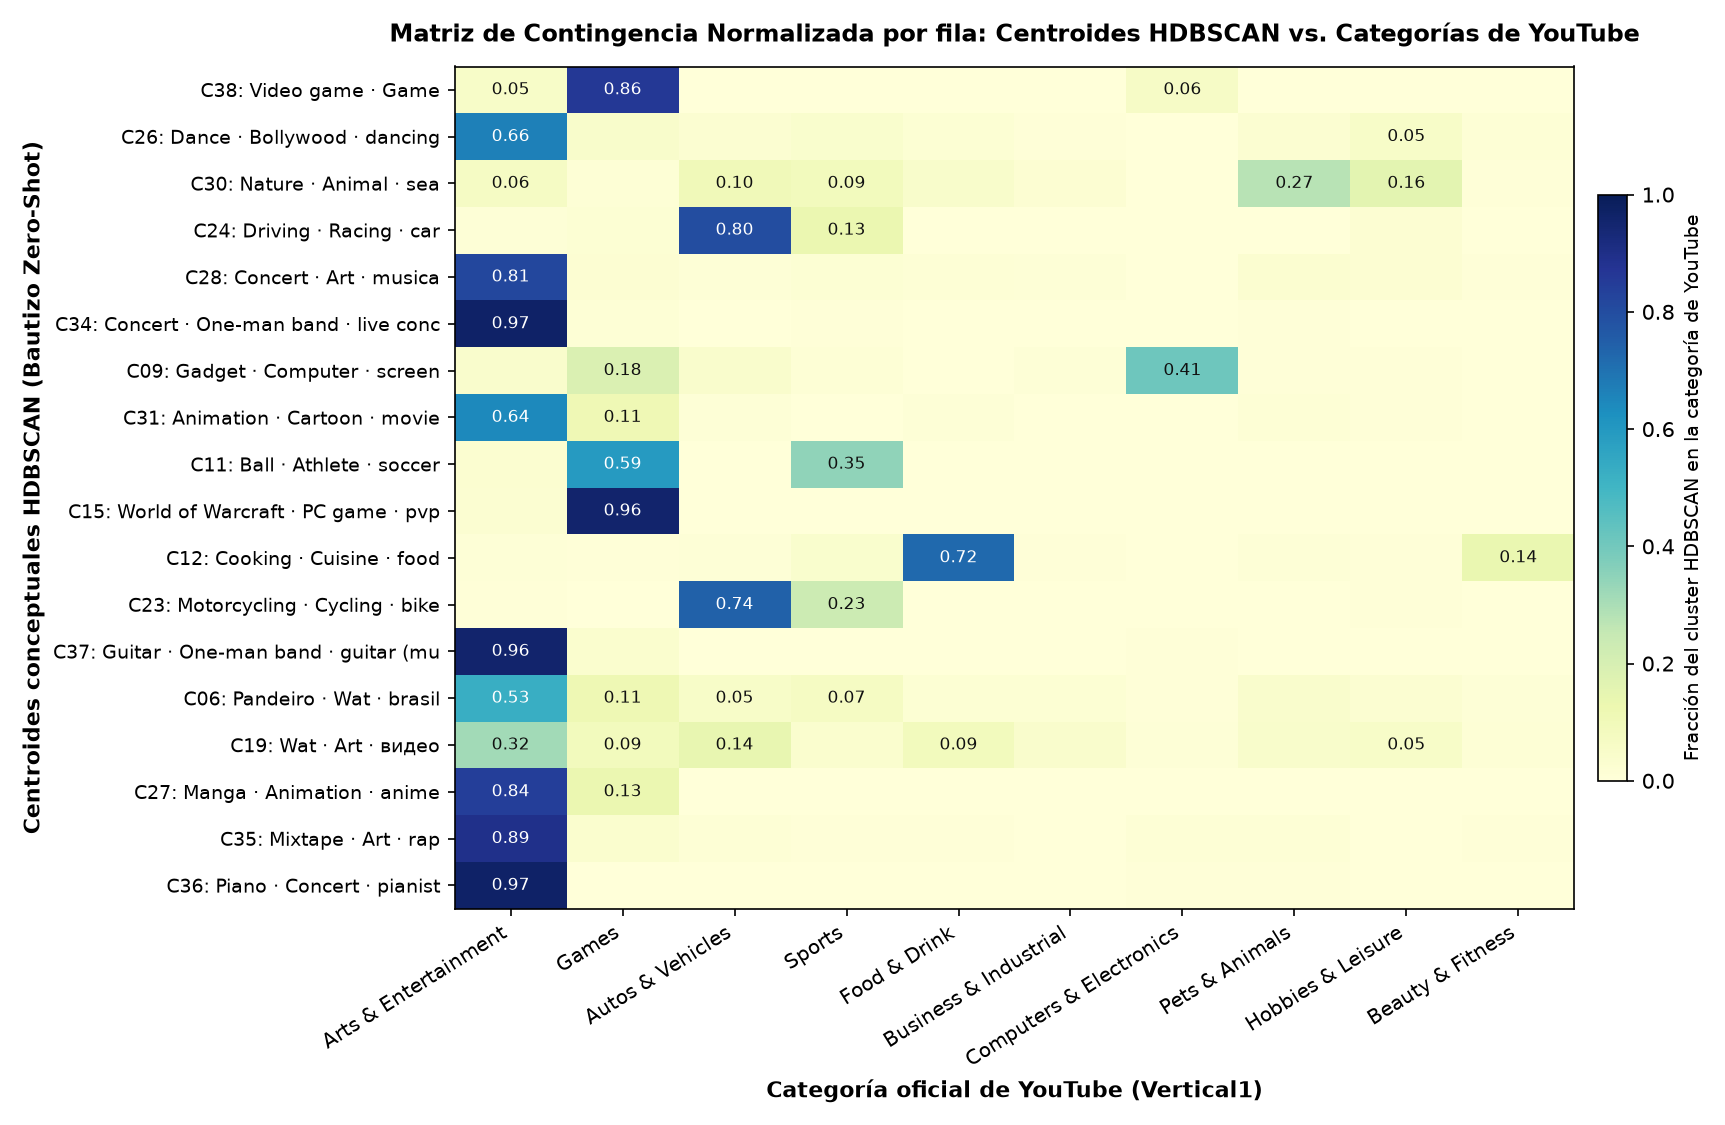

In [5]:
Path("informe/figs").mkdir(parents=True, exist_ok=True)
valid_mask = yt_cats != "(Unknown)"
top_yt = [v for v, _ in Counter(yt_cats[valid_mask]).most_common(10)]
top_cl = clusters_df.head(18)["cluster_id"].tolist()
cl_label_map = {r["cluster_id"]: "C{:02d}: {}".format(r["cluster_id"], r["short_name"][:34]) for r in cluster_records}

mat = np.zeros((len(top_cl), len(top_yt)), dtype=float)
for i, cid in enumerate(top_cl):
    mask = assigned_labels == cid
    total_c = max(1, int(mask.sum()))
    counts_c = Counter(yt_cats[mask])
    for j, yv in enumerate(top_yt):
        mat[i, j] = counts_c.get(yv, 0) / total_c

fig1, ax1 = plt.subplots(figsize=(11.5, 7.5), dpi=150)
im = ax1.imshow(mat, cmap="YlGnBu", aspect="auto", vmin=0, vmax=1.0)
ax1.set_xticks(range(len(top_yt)))
ax1.set_xticklabels(top_yt, rotation=32, ha="right", fontsize=9.5)
ax1.set_yticks(range(len(top_cl)))
ax1.set_yticklabels([cl_label_map[c] for c in top_cl], fontsize=9)
ax1.set_xlabel("Categoría oficial de YouTube (Vertical1)", fontsize=10.5, fontweight="bold")
ax1.set_ylabel("Centroides conceptuales HDBSCAN (Bautizo Zero-Shot)", fontsize=10.5, fontweight="bold")
ax1.set_title("Matriz de Contingencia Normalizada por fila: Centroides HDBSCAN vs. Categorías de YouTube", fontsize=11.5, fontweight="bold", pad=12)

for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        val = mat[i, j]
        if val >= 0.05:
            ax1.text(j, i, f"{val:.2f}", ha="center", va="center", color="white" if val > 0.52 else "#111", fontsize=8)

cbar = fig1.colorbar(im, ax=ax1, fraction=0.025, pad=0.02)
cbar.set_label("Fracción del cluster HDBSCAN en la categoría de YouTube", fontsize=9)
fig1.tight_layout()
fig1.savefig("informe/figs/hdbscan_matriz_confusion.png")

## 5. Diagrama de Flujo Semántico (Alluvial / Sankey Bipartito)

Visualizamos cómo se redistribuyen los videos desde las 8 categorías más grandes de YouTube (izquierda) hacia los 12 mayores centroides conceptuales descubiertos por HDBSCAN (derecha). Se observa cómo *Arts & Entertainment* y *Games* se ramifican en comunidades específicas (conciertos en vivo, danza/coreografías, animación, MMORPGs como *World of Warcraft*, deportes de balón, etc.).

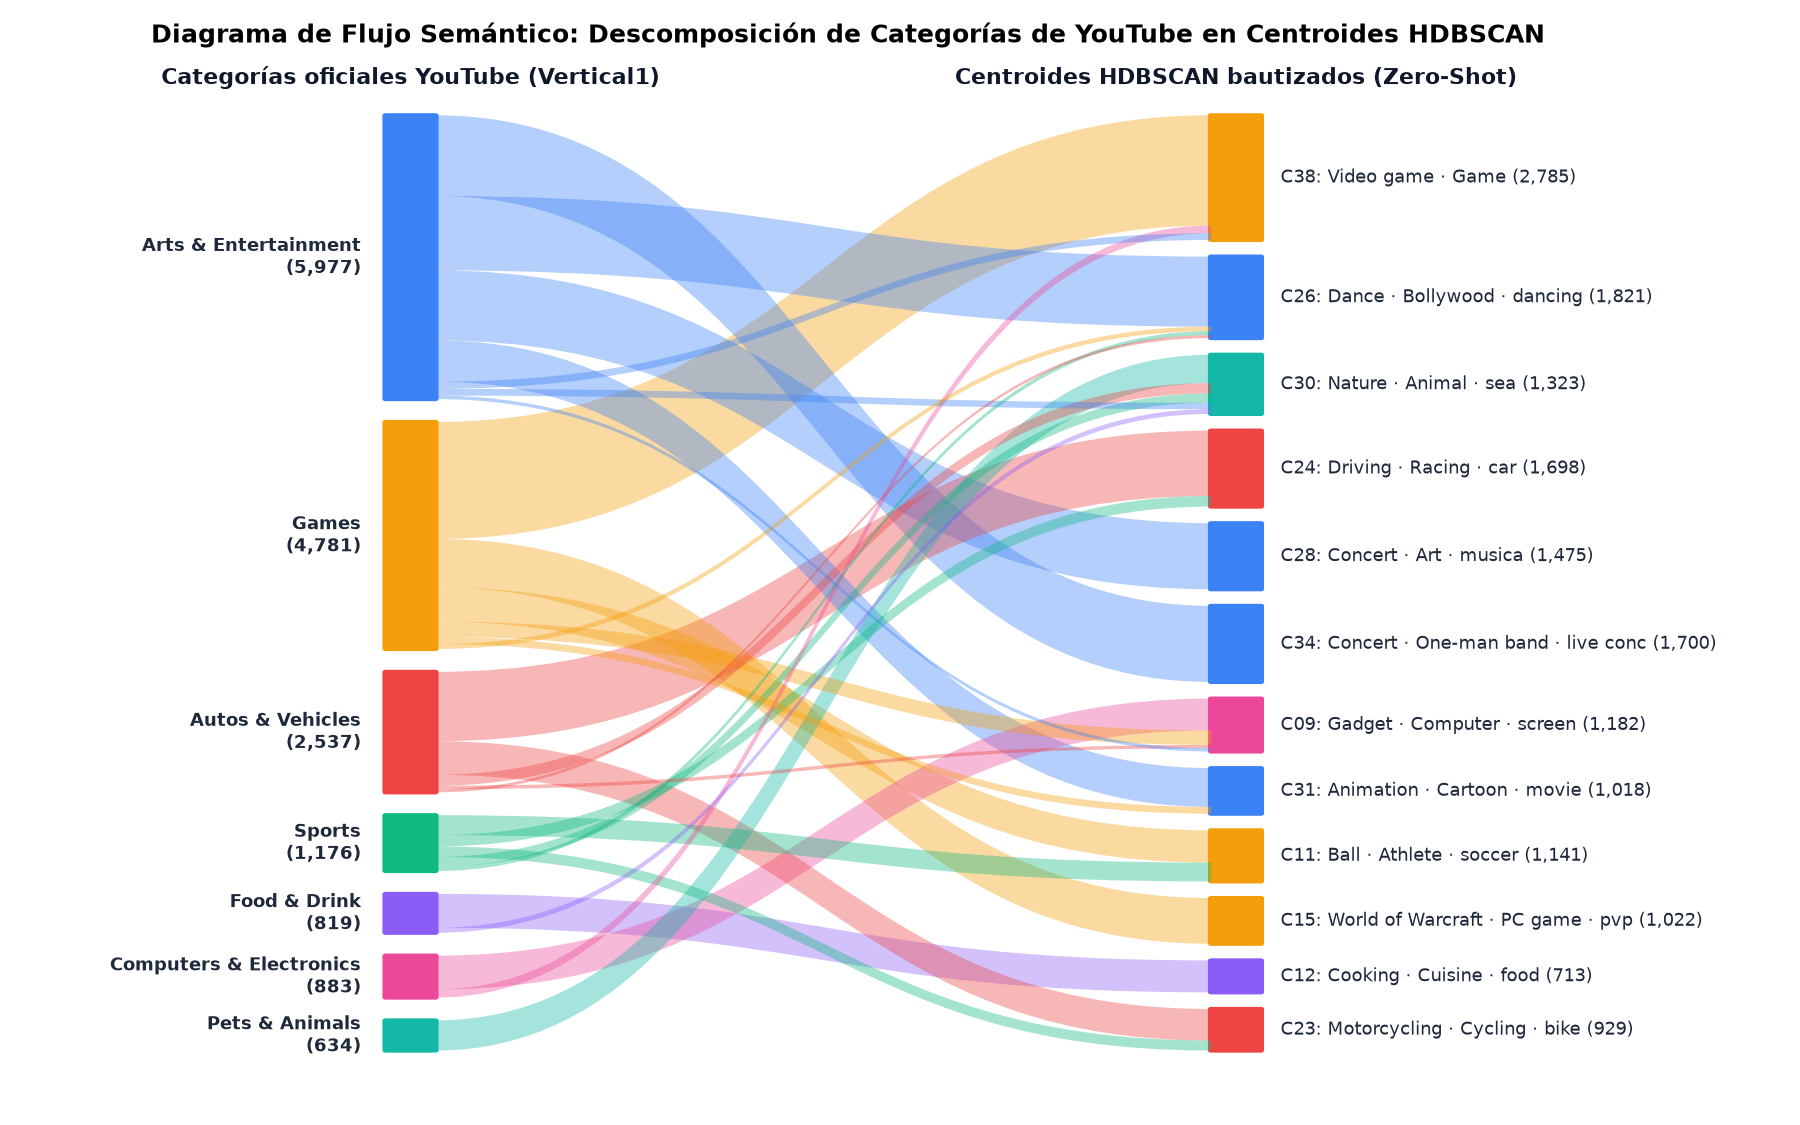

In [6]:
top_yt_flow = [v for v, _ in Counter(yt_cats[valid_mask]).most_common(8)]
top_cl_flow = clusters_df.head(12)["cluster_id"].tolist()

flow_pairs = []
for yv in top_yt_flow:
    for cid in top_cl_flow:
        cnt = int(((yt_cats == yv) & (assigned_labels == cid)).sum())
        if cnt >= 60:
            flow_pairs.append((yv, cid, cnt))

yt_totals = {yv: sum(c for y, _, c in flow_pairs if y == yv) for yv in top_yt_flow}
cl_totals = {cid: sum(c for _, cl, c in flow_pairs if cl == cid) for cid in top_cl_flow}
top_yt_flow = [yv for yv in top_yt_flow if yt_totals.get(yv, 0) > 0]
top_cl_flow = [cid for cid in top_cl_flow if cl_totals.get(cid, 0) > 0]
grand_total = sum(c for _, _, c in flow_pairs)

fig2, ax2 = plt.subplots(figsize=(12, 7.5), dpi=150)
ax2.set_xlim(0, 1)
ax2.set_ylim(0, 1)
ax2.axis("off")

palette_yt = ["#3B82F6", "#F59E0B", "#EF4444", "#10B981", "#8B5CF6", "#EC4899", "#14B8A6", "#F97316"]
yt_colors = {yv: palette_yt[i % len(palette_yt)] for i, yv in enumerate(top_yt_flow)}

gap_l = 0.022
usable_l = 0.90 - gap_l * (len(top_yt_flow) - 1)
y_cursor = 0.95
yt_boxes = {}
for yv in top_yt_flow:
    h = usable_l * (yt_totals[yv] / grand_total)
    yt_boxes[yv] = [y_cursor - h, y_cursor, y_cursor]
    rect = patches.FancyBboxPatch((0.22, y_cursor - h), 0.03, h, boxstyle="round,pad=0.002", facecolor=yt_colors[yv], edgecolor="none")
    ax2.add_patch(rect)
    ax2.text(0.205, y_cursor - h / 2, "{}\n({:,})".format(yv, yt_totals[yv]), ha="right", va="center", fontsize=8.8, fontweight="bold", color="#1E293B")
    y_cursor -= (h + gap_l)

gap_r = 0.016
usable_r = 0.90 - gap_r * (len(top_cl_flow) - 1)
y_cursor = 0.95
cl_boxes = {}
for cid in top_cl_flow:
    h = usable_r * (cl_totals[cid] / grand_total)
    cl_boxes[cid] = [y_cursor - h, y_cursor, y_cursor]
    dom_v = next(r["dominant_youtube_vertical"] for r in cluster_records if r["cluster_id"] == cid)
    c_hex = yt_colors.get(dom_v, "#64748B")
    rect = patches.FancyBboxPatch((0.72, y_cursor - h), 0.03, h, boxstyle="round,pad=0.002", facecolor=c_hex, edgecolor="none")
    ax2.add_patch(rect)
    ax2.text(0.762, y_cursor - h / 2, "{} ({:,})".format(cl_label_map[cid], cl_totals[cid]), ha="left", va="center", fontsize=8.5, color="#1E293B")
    y_cursor -= (h + gap_r)

for yv, cid, cnt in sorted(flow_pairs, key=lambda x: -x[2]):
    h_l = usable_l * (cnt / grand_total)
    h_r = usable_r * (cnt / grand_total)
    y_l_top = yt_boxes[yv][2]
    y_l_bot = y_l_top - h_l
    yt_boxes[yv][2] = y_l_bot

    y_r_top = cl_boxes[cid][2]
    y_r_bot = y_r_top - h_r
    cl_boxes[cid][2] = y_r_bot

    verts = [
        (0.25, y_l_top), (0.48, y_l_top), (0.49, y_r_top), (0.72, y_r_top),
        (0.72, y_r_bot), (0.49, y_r_bot), (0.48, y_l_bot), (0.25, y_l_bot), (0.25, y_l_top),
    ]
    codes = [
        MplPath.MOVETO, MplPath.CURVE4, MplPath.CURVE4, MplPath.CURVE4,
        MplPath.LINETO, MplPath.CURVE4, MplPath.CURVE4, MplPath.CURVE4, MplPath.CLOSEPOLY,
    ]
    ax2.add_patch(patches.PathPatch(MplPath(verts, codes), facecolor=yt_colors[yv], alpha=0.38, edgecolor="none"))

ax2.text(0.235, 0.975, "Categorías oficiales YouTube (Vertical1)", ha="center", va="bottom", fontsize=10.5, fontweight="bold", color="#0F172A")
ax2.text(0.735, 0.975, "Centroides HDBSCAN bautizados (Zero-Shot)", ha="center", va="bottom", fontsize=10.5, fontweight="bold", color="#0F172A")
ax2.set_title("Diagrama de Flujo Semántico: Descomposición de Categorías de YouTube en Centroides HDBSCAN", fontsize=12, fontweight="bold", pad=10)
fig2.tight_layout()
fig2.savefig("informe/figs/hdbscan_flujo_categorias.png")